In [3]:
import pandas as pd
import numpy as np
import os
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr
from sklearn.model_selection import KFold
import xgboost as xgb
import lightgbm as lgb
import catboost
import warnings

# 忽略一些不必要的警告
warnings.filterwarnings('ignore')

# ============ 路径与参数 =================
file_path = r"C:\Users\greenlandProject\ERA5LAND\merged_allfeature.csv"
output_csv = r"C:\Users\greenlandProject\ERA5LAND\siteaccuracy.csv"

target_column = "albedo"
input_features = [
    "longitude", "latitude", "altitude_last_valid", "sp", "ssrd", "str", "strd",
    "t2m", "u10", "v10", "snowc", "sde", "asn", "year", "month"
]
exclude_stations = ["QAS_M", "MIT", "NUK_K"]

# ============ 读取与预处理 =================
data = pd.read_csv(file_path)
data = data[~data["station"].isin(exclude_stations)]
data = data[data["year"] >= 1995]

# 获取站点地理信息映射表（去重，取第一行即可）
geo_map = data.groupby("station")[["longitude", "latitude", "altitude_last_valid"]].first()

all_stations = data["station"].unique()

# ============ 模型设置 =================
models = {
    "RF": RandomForestRegressor(n_jobs=-1, random_state=42),
    "XGB": xgb.XGBRegressor(n_jobs=-1, random_state=42, verbosity=0),
    "GBDT": GradientBoostingRegressor(random_state=42),
    "LGBM": lgb.LGBMRegressor(n_jobs=-1, random_state=42, verbosity=-1),
    "CatBoost": catboost.CatBoostRegressor(verbose=0, random_seed=42),
}

results_list = []

print(f"开始计算，共计 {len(all_stations)} 个站点...\n")

# ============ 留一站点交叉验证 =================
for i, test_station in enumerate(all_stations):
    try:
        # 划分训练/测试
        train_data = data[data["station"] != test_station]
        test_data = data[data["station"] == test_station]

        if len(test_data) < 2:
            print(f"⚠️ 跳过站点 {test_station}: 样本量不足({len(test_data)})")
            continue

        X_train = train_data[input_features].astype(float)
        y_train = train_data[target_column].astype(float)
        X_test = test_data[input_features].astype(float)
        y_test = test_data[target_column].astype(float)

        # ----- Stacking Meta-features (KFold) -----
        kf = KFold(n_splits=5, shuffle=True, random_state=42)
        meta_features = np.zeros((X_train.shape[0], len(models)))

        for idx, (name, model) in enumerate(models.items()):
            meta_feature = np.zeros(X_train.shape[0])
            for train_idx, val_idx in kf.split(X_train):
                model.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
                meta_feature[val_idx] = model.predict(X_train.iloc[val_idx])
            meta_features[:, idx] = meta_feature

        # ----- 元模型 (Ridge) -----
        meta_model = Ridge()
        meta_model.fit(meta_features, y_train)

        # ----- 基础模型重训 -----
        trained_base_models = []
        for name, model in models.items():
            model.fit(X_train, y_train)
            trained_base_models.append(model)

        # ----- 预测与评估 -----
        test_meta_features = np.column_stack([m.predict(X_test) for m in trained_base_models])
        final_preds = meta_model.predict(test_meta_features)

        r, _ = pearsonr(y_test, final_preds)
        r2 = r ** 2
        rmse = np.sqrt(mean_squared_error(y_test, final_preds))
        bias = np.mean(final_preds - y_test)

        # 获取该站点的地理信息
        lon = geo_map.loc[test_station, "longitude"]
        lat = geo_map.loc[test_station, "latitude"]
        alt = geo_map.loc[test_station, "altitude_last_valid"]

        # 存入结果列表
        results_list.append([test_station, lon, lat, alt, r2, r, rmse, bias])
        
        print(f"[{i+1}/{len(all_stations)}] {test_station}: R²={r2:.3f}, RMSE={rmse:.4f} (完成)")

    except Exception as e:
        print(f"❌ 站点 {test_station} 计算出错: {e}")
        continue

# ============ 导出 CSV =================
columns = ["station", "longitude", "latitude", "altitude_last_valid", "R_squared", "R", "RMSE", "Bias"]
final_df = pd.DataFrame(results_list, columns=columns)

final_df.to_csv(output_csv, index=False, encoding='utf-8-sig')

print("-" * 30)
print(f"✅ 所有站点计算完毕！结果已存至: {output_csv}")
print(f"成功计算站点数: {len(final_df)} / 总计: {len(all_stations)}")

开始计算，共计 46 个站点...

[1/46] CEN: R²=0.002, RMSE=0.0527 (完成)
[2/46] CP1: R²=0.350, RMSE=0.0612 (完成)
[3/46] DY2: R²=0.554, RMSE=0.0315 (完成)
[4/46] EGP: R²=0.077, RMSE=0.0507 (完成)
[5/46] FRE: R²=0.805, RMSE=0.1953 (完成)
[6/46] HUM: R²=0.081, RMSE=0.0307 (完成)
[7/46] JAR: R²=0.663, RMSE=0.0965 (完成)
[8/46] KAN_B: R²=0.522, RMSE=0.2562 (完成)
[9/46] KAN_L: R²=0.615, RMSE=0.0980 (完成)
[10/46] KAN_M: R²=0.676, RMSE=0.1158 (完成)
[11/46] KAN_T: R²=0.737, RMSE=0.1514 (完成)
[12/46] KAN_U: R²=0.372, RMSE=0.0449 (完成)
[13/46] KPC_L: R²=0.735, RMSE=0.1089 (完成)
[14/46] KPC_U: R²=0.777, RMSE=0.1452 (完成)
[15/46] LYN_L: R²=0.604, RMSE=0.1122 (完成)
[16/46] LYN_T: R²=0.654, RMSE=0.1940 (完成)
[17/46] NAE: R²=0.109, RMSE=0.0502 (完成)
[18/46] NAU: R²=0.296, RMSE=0.0557 (完成)
[19/46] NEM: R²=0.178, RMSE=0.0296 (完成)
[20/46] NSE: R²=0.079, RMSE=0.0355 (完成)
[21/46] NUK_L: R²=0.673, RMSE=0.1318 (完成)
[22/46] NUK_N: R²=0.867, RMSE=0.1346 (完成)
[23/46] NUK_U: R²=0.625, RMSE=0.0781 (完成)
[24/46] QAS_A: R²=0.855, RMSE=0.0862 (完成)
[25/

In [ ]:
#滑动窗口验证---------------------五年为单位-----------------
========== Summary of All 5-Year Windows ==========
1990-1994 -> R²: -12.194, R: 0.637, RMSE: 0.149, Bias: -0.139
1995-1999 -> R²: 0.166, R: 0.669, RMSE: 0.060, Bias: 0.034
2000-2004 -> R²: 0.727, R: 0.853, RMSE: 0.038, Bias: -0.001
2005-2009 -> R²: 0.859, R: 0.930, RMSE: 0.063, Bias: -0.013
2010-2014 -> R²: 0.875, R: 0.937, RMSE: 0.068, Bias: 0.010
2015-2019 -> R²: 0.881, R: 0.939, RMSE: 0.066, Bias: -0.004
2020-2024 -> R²: 0.723, R: 0.858, RMSE: 0.103, Bias: -0.005
因为1990-1994效果差，样本量极少，因此决定剔除出训练


================ Year Window: 1995-1999 ==================
Training base model: RF
RF CV - R2: 0.871, R: 0.933, RMSE: 0.067, Bias: -0.000
Training base model: XGB
XGB CV - R2: 0.873, R: 0.934, RMSE: 0.066, Bias: 0.001
Training base model: GBDT
GBDT CV - R2: 0.850, R: 0.922, RMSE: 0.072, Bias: 0.000
Training base model: LGBM
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000577 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2699
[LightGBM] [Info] Number of data points in the train set: 3128, number of used features: 49
[LightGBM] [Info] Start training from score 0.720842
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000575 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2708
[LightGBM] [Info] Number of data points in the train set: 3128, number of used features: 49
[LightGBM] [Info] Start training from score 

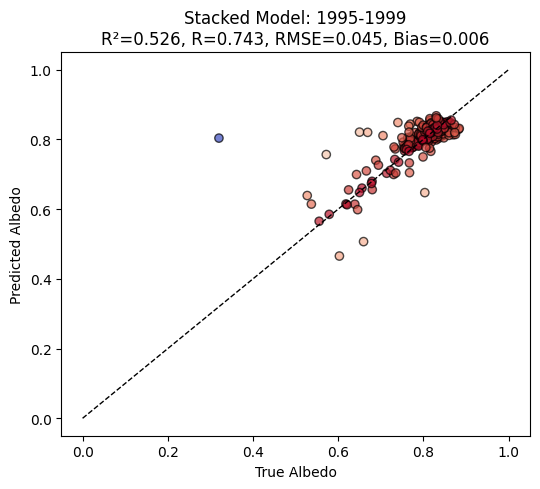


================ Year Window: 2000-2004 ==================
Training base model: RF
RF CV - R2: 0.867, R: 0.931, RMSE: 0.068, Bias: -0.000
Training base model: XGB
XGB CV - R2: 0.871, R: 0.934, RMSE: 0.067, Bias: 0.000
Training base model: GBDT
GBDT CV - R2: 0.843, R: 0.918, RMSE: 0.074, Bias: -0.000
Training base model: LGBM
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000737 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2715
[LightGBM] [Info] Number of data points in the train set: 3080, number of used features: 49
[LightGBM] [Info] Start training from score 0.718434
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000572 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2715
[LightGBM] [Info] Number of data points in the train set: 3081, number of used features: 49
[LightGBM] [Info] Start training from score

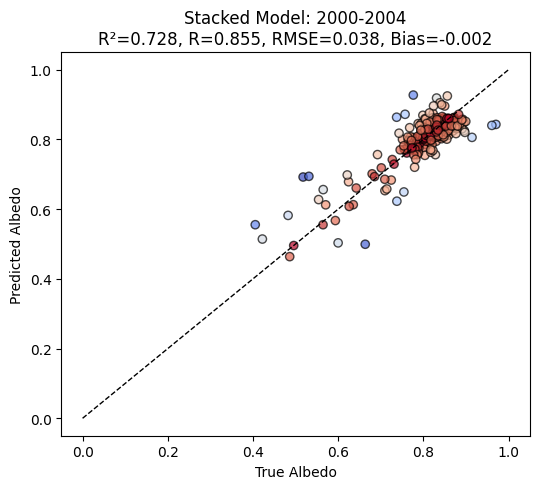


================ Year Window: 2005-2009 ==================
Training base model: RF
RF CV - R2: 0.866, R: 0.931, RMSE: 0.067, Bias: -0.001
Training base model: XGB
XGB CV - R2: 0.866, R: 0.931, RMSE: 0.067, Bias: -0.000
Training base model: GBDT
GBDT CV - R2: 0.844, R: 0.919, RMSE: 0.072, Bias: 0.000
Training base model: LGBM
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000641 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2714
[LightGBM] [Info] Number of data points in the train set: 2966, number of used features: 49
[LightGBM] [Info] Start training from score 0.722143
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000664 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2701
[LightGBM] [Info] Number of data points in the train set: 2966, number of used features: 49
[LightGBM] [Info] Start training from score

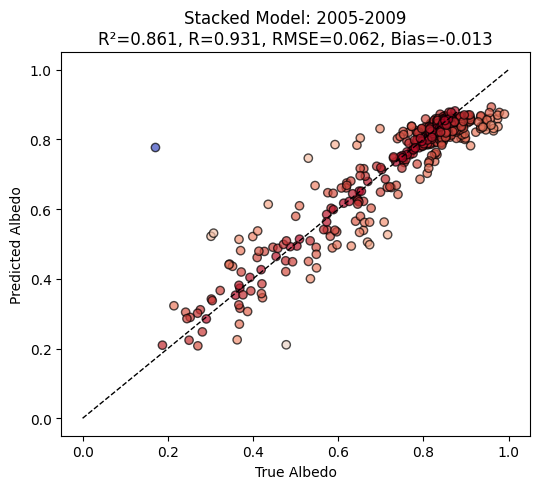


================ Year Window: 2010-2014 ==================
Training base model: RF
RF CV - R2: 0.858, R: 0.927, RMSE: 0.067, Bias: -0.000
Training base model: XGB
XGB CV - R2: 0.857, R: 0.926, RMSE: 0.067, Bias: 0.001
Training base model: GBDT
GBDT CV - R2: 0.838, R: 0.916, RMSE: 0.071, Bias: -0.000
Training base model: LGBM
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000692 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2675
[LightGBM] [Info] Number of data points in the train set: 2598, number of used features: 47
[LightGBM] [Info] Start training from score 0.734150
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000644 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2670
[LightGBM] [Info] Number of data points in the train set: 2598, number of used features: 47
[LightGBM] [Info] Start training from score

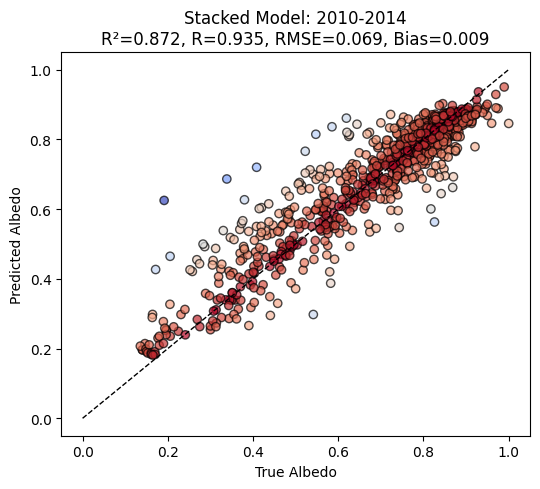


================ Year Window: 2015-2019 ==================
Training base model: RF
RF CV - R2: 0.859, R: 0.927, RMSE: 0.067, Bias: -0.001
Training base model: XGB
XGB CV - R2: 0.865, R: 0.930, RMSE: 0.065, Bias: 0.000
Training base model: GBDT
GBDT CV - R2: 0.840, R: 0.917, RMSE: 0.071, Bias: 0.000
Training base model: LGBM
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000540 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2680
[LightGBM] [Info] Number of data points in the train set: 2532, number of used features: 48
[LightGBM] [Info] Start training from score 0.727097
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000536 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2683
[LightGBM] [Info] Number of data points in the train set: 2532, number of used features: 48
[LightGBM] [Info] Start training from score 

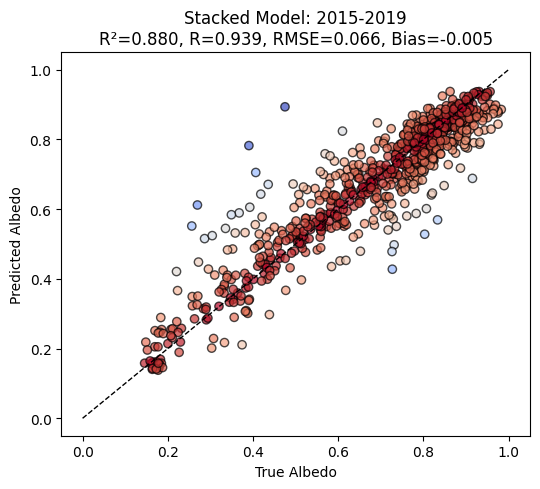


================ Year Window: 2020-2024 ==================
Training base model: RF
RF CV - R2: 0.874, R: 0.935, RMSE: 0.062, Bias: -0.000
Training base model: XGB
XGB CV - R2: 0.869, R: 0.932, RMSE: 0.063, Bias: 0.001
Training base model: GBDT
GBDT CV - R2: 0.863, R: 0.929, RMSE: 0.065, Bias: 0.000
Training base model: LGBM
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000643 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2414
[LightGBM] [Info] Number of data points in the train set: 2486, number of used features: 48
[LightGBM] [Info] Start training from score 0.736702
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000601 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2408
[LightGBM] [Info] Number of data points in the train set: 2486, number of used features: 49
[LightGBM] [Info] Start training from score 

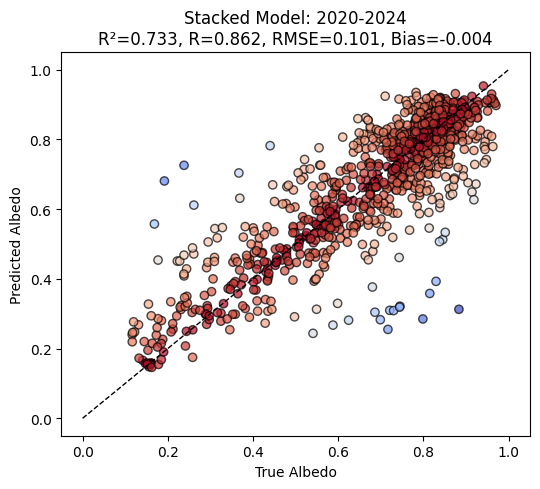


✅ stacking_model.pkl saved successfully.

========== Summary of All 5-Year Windows ==========
1995-1999 -> R²: 0.526, R: 0.743, RMSE: 0.045, Bias: 0.006
2000-2004 -> R²: 0.728, R: 0.855, RMSE: 0.038, Bias: -0.002
2005-2009 -> R²: 0.861, R: 0.931, RMSE: 0.062, Bias: -0.013
2010-2014 -> R²: 0.872, R: 0.935, RMSE: 0.069, Bias: 0.009
2015-2019 -> R²: 0.880, R: 0.939, RMSE: 0.066, Bias: -0.005
2020-2024 -> R²: 0.733, R: 0.862, RMSE: 0.101, Bias: -0.004


In [3]:
#------------滑动窗口验证---------------------五年为单位----------------1995-2024-----------
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_squared_error
from scipy.stats import pearsonr
from sklearn.model_selection import KFold
import xgboost as xgb
import lightgbm as lgb
import catboost
import matplotlib.pyplot as plt
import joblib

# ---------- 配置参数 ----------
file_path = "F:/TUB/greenlandProject/ERA5LAND/merged_allfeature.csv"
exclude_stations = ["QAS_M", "MIT", "NUK_K"]
input_features = [
    "longitude", "latitude", "altitude_last_valid", "sp", "ssrd", "str", "strd",
    "t2m", "u10", "v10", "snowc", "sde", "asn", "year", "month"
]
target_column = "albedo"

# ---------- 数据读取与预处理 ----------
data = pd.read_csv(file_path)
data = data[~data["station"].isin(exclude_stations)]
# Add the new filtering condition: year must be 1995 or greater
data = data[data["year"] >= 1995]

# GeoShapley 编码
data["geo_shapley"] = data[["longitude", "latitude", "altitude_last_valid"]].apply(lambda row: hash(tuple(row)), axis=1)
data["geo_shapley"] = data["geo_shapley"].astype(str)
data = pd.get_dummies(data, columns=["geo_shapley"], drop_first=True)

X = data.drop(columns=[target_column, "station"])
y = data[target_column]
X = X.astype(float)

# ---------- 模型定义 ----------
base_models = {
    'RF': RandomForestRegressor(n_jobs=-1, random_state=42),
    'XGB': xgb.XGBRegressor(n_jobs=-1, random_state=42),
    'GBDT': GradientBoostingRegressor(random_state=42),
    'LGBM': lgb.LGBMRegressor(n_jobs=-1, random_state=42),
    'CatBoost': catboost.CatBoostRegressor(verbose=0, random_seed=42)
}

# ---------- 散点图函数 ----------
def plot_scatter(y_true, y_pred, title):
    error = np.abs(y_true - y_pred)
    colors = plt.cm.coolwarm(1 - error / np.max(error))
    plt.figure(figsize=(5.5, 5))
    plt.scatter(y_true, y_pred, c=colors, edgecolor='k', alpha=0.7)
    plt.plot([0, 1], [0, 1], 'k--', lw=1)
    r2 = r2_score(y_true, y_pred)
    r, _ = pearsonr(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    bias = np.mean(y_pred - y_true)
    plt.title(f"{title}\nR²={r2:.3f}, R={r:.3f}, RMSE={rmse:.3f}, Bias={bias:.3f}")
    plt.xlabel("True Albedo")
    plt.ylabel("Predicted Albedo")
    plt.tight_layout()
    plt.show()

# ---------- 滑动窗口训练 ----------
overall_results = []

# Adjusted starting year for the loop to reflect the new data filtering
for start_year in range(1995, 2021, 5):
    print(f"\n================ Year Window: {start_year}-{start_year+4} ==================")
    
    test_mask = (X["year"] >= start_year) & (X["year"] <= start_year + 4)
    train_mask = ~test_mask

    X_train, y_train = X[train_mask], y[train_mask]
    X_test, y_test = X[test_mask], y[test_mask]

    # Skip if test set is empty (can happen at the end of the data if window extends beyond available years)
    if X_test.empty:
        print(f"No data for test window {start_year}-{start_year+4}. Skipping.")
        continue
    # Skip if training set is empty
    if X_train.empty:
        print(f"No data for training for window {start_year}-{start_year+4}. Skipping.")
        continue


    # ----- 生成元特征 -----
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    meta_features = np.zeros((X_train.shape[0], len(base_models)))
    model_statistics = {}
    trained_base_models = []

    for idx, (name, model) in enumerate(base_models.items()):
        print(f"Training base model: {name}")
        meta_feature = np.zeros(X_train.shape[0])
        for train_idx, val_idx in kf.split(X_train):
            X_t, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
            y_t, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
            model.fit(X_t, y_t)
            preds = model.predict(X_val)
            meta_feature[val_idx] = preds

        meta_features[:, idx] = meta_feature
        r2 = r2_score(y_train, meta_feature)
        r, _ = pearsonr(y_train, meta_feature)
        mse = mean_squared_error(y_train, meta_feature)
        rmse = np.sqrt(mse)
        bias = np.mean(meta_feature - y_train)
        model_statistics[name] = {"R2": r2, "R": r, "RMSE": rmse, "Bias": bias}
        print(f"{name} CV - R2: {r2:.3f}, R: {r:.3f}, RMSE: {rmse:.3f}, Bias: {bias:.3f}")

        # 用于 test 时的模型也训练好
        model.fit(X_train, y_train)
        trained_base_models.append(model)

    # ----- 元模型训练 -----
    meta_model = Ridge()
    meta_model.fit(meta_features, y_train)

    # ----- 测试集预测 -----
    test_meta_features = np.column_stack([model.predict(X_test) for model in trained_base_models])
    final_preds = meta_model.predict(test_meta_features)

    # ----- 输出堆叠模型结果 -----
    r2 = r2_score(y_test, final_preds)
    r, _ = pearsonr(y_test, final_preds)
    mse = mean_squared_error(y_test, final_preds)
    rmse = np.sqrt(mse)
    bias = np.mean(final_preds - y_test)

    print(f"\n📊 Stacked Model Performance on {start_year}-{start_year+4} Test Set:")
    print(f"R²: {r2:.6f}")
    print(f"Pearson R: {r:.6f}")
    print(f"RMSE: {rmse:.6f}")
    print(f"MSE: {mse:.6f}")
    print(f"Bias: {bias:.6f}")

    plot_scatter(y_test, final_preds, title=f"Stacked Model: {start_year}-{start_year+4}")

    # 保存本轮结果
    overall_results.append({
        "start_year": start_year,
        "r2": r2,
        "r": r,
        "rmse": rmse,
        "bias": bias
    })

# ---------- 保存最终模型 ----------
# Ensure that start_year is defined for the last window (if the loop completed)
if overall_results: # Check if any results were recorded
    last_processed_year_window = f"{overall_results[-1]['start_year']}-{overall_results[-1]['start_year']+4}"
else:
    last_processed_year_window = "No windows processed"

stacking_model = {
    'trained_base_models': trained_base_models,
    'meta_model': meta_model,
    'model_statistics': model_statistics,
    'last_window': last_processed_year_window
}

joblib.dump(stacking_model, "stacking_model.pkl")
print("\n✅ stacking_model.pkl saved successfully.")

# ---------- 汇总输出 ----------
print("\n========== Summary of All 5-Year Windows ==========")
for res in overall_results:
    print(f"{res['start_year']}-{res['start_year']+4} -> R²: {res['r2']:.3f}, R: {res['r']:.3f}, RMSE: {res['rmse']:.3f}, Bias: {res['bias']:.3f}")

统计指标：
相关系数 (Correlation): 0.3646
偏差 (Bias): 0.1148
方差 (Variance of error): 0.0302
均方误差 (MSE): 0.0434
均方根误差 (RMSE): 0.2084
平均绝对误差 (MAE): 0.1323
R²: -0.2615


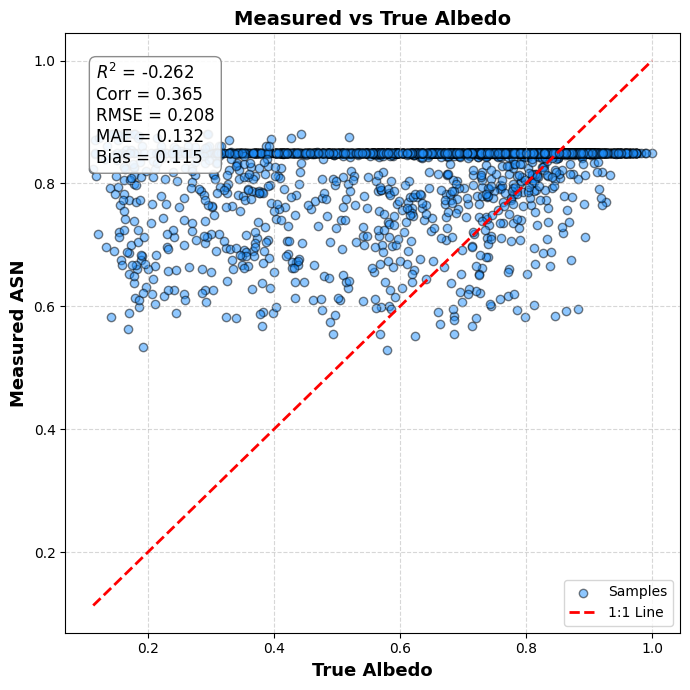

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 读取数据
df = pd.read_csv("F:/TUB/greenlandProject/ERA5LAND/merged_allfeature.csv")

# 提取真值和预测值
y_true = df['albedo']
y_pred = df['asn']

# 计算统计指标
correlation = y_true.corr(y_pred)
bias = np.mean(y_pred - y_true)
variance = np.var(y_pred - y_true)
mse = mean_squared_error(y_true, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_true, y_pred)
r2 = r2_score(y_true, y_pred)

# 打印统计值
print("统计指标：")
print(f"相关系数 (Correlation): {correlation:.4f}")
print(f"偏差 (Bias): {bias:.4f}")
print(f"方差 (Variance of error): {variance:.4f}")
print(f"均方误差 (MSE): {mse:.4f}")
print(f"均方根误差 (RMSE): {rmse:.4f}")
print(f"平均绝对误差 (MAE): {mae:.4f}")
print(f"R²: {r2:.4f}")

# 绘图
plt.figure(figsize=(7, 7))
plt.scatter(y_true, y_pred, c='dodgerblue', edgecolors='k', alpha=0.5, label='Samples')
plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], 'r--', lw=2, label='1:1 Line')

# 文字框显示统计值
textstr = '\n'.join((
    f'$R^2$ = {r2:.3f}',
    f'Corr = {correlation:.3f}',
    f'RMSE = {rmse:.3f}',
    f'MAE = {mae:.3f}',
    f'Bias = {bias:.3f}',
))

props = dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor='gray', alpha=0.9)
plt.text(0.05, 0.95, textstr, transform=plt.gca().transAxes, fontsize=12,
         verticalalignment='top', bbox=props)

# 坐标轴与标签
plt.xlabel('True Albedo', fontsize=13, weight='bold')
plt.ylabel('Measured ASN', fontsize=13, weight='bold')
plt.title('Measured vs True Albedo', fontsize=14, weight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()



===== Processing Variable: SSRD =====


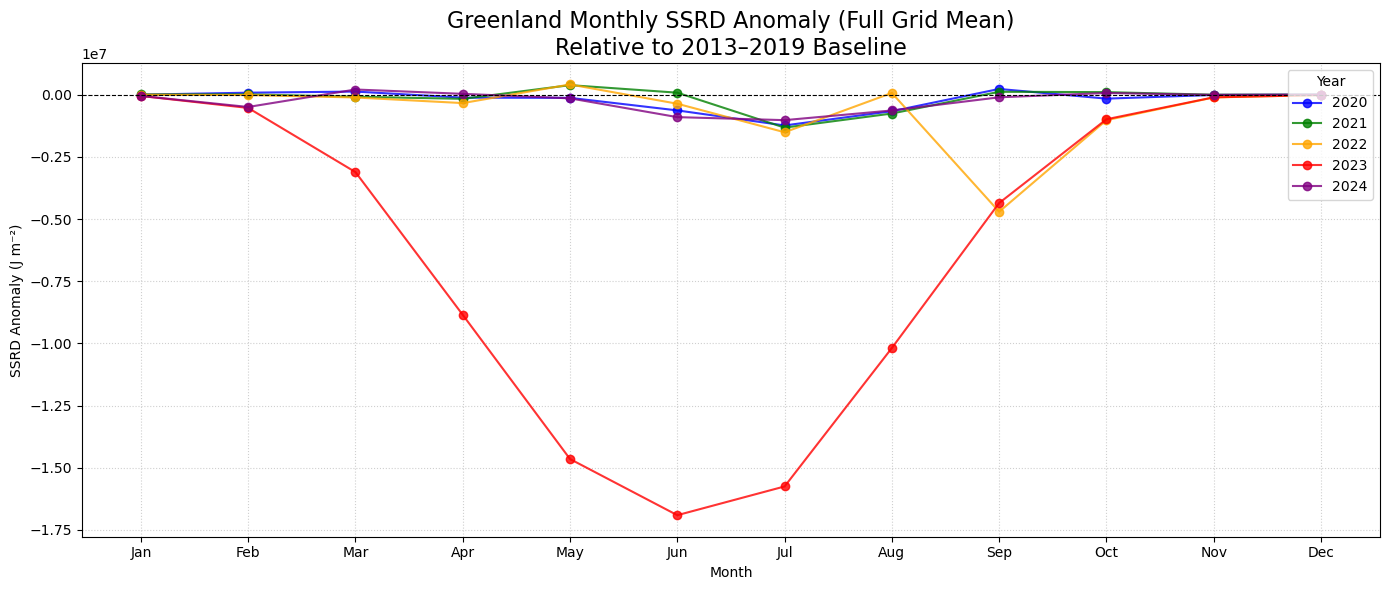


==== SSRD Monthly Anomaly Summary (2020-2024) ====
2020 Average Anomaly: -2.10e+05 J/m²
2021 Average Anomaly: -1.37e+05 J/m²
2022 Average Anomaly: -6.44e+05 J/m²
2023 Average Anomaly: -6.29e+06 J/m²
2024 Average Anomaly: -2.56e+05 J/m²

===== Processing Variable: SLHF =====


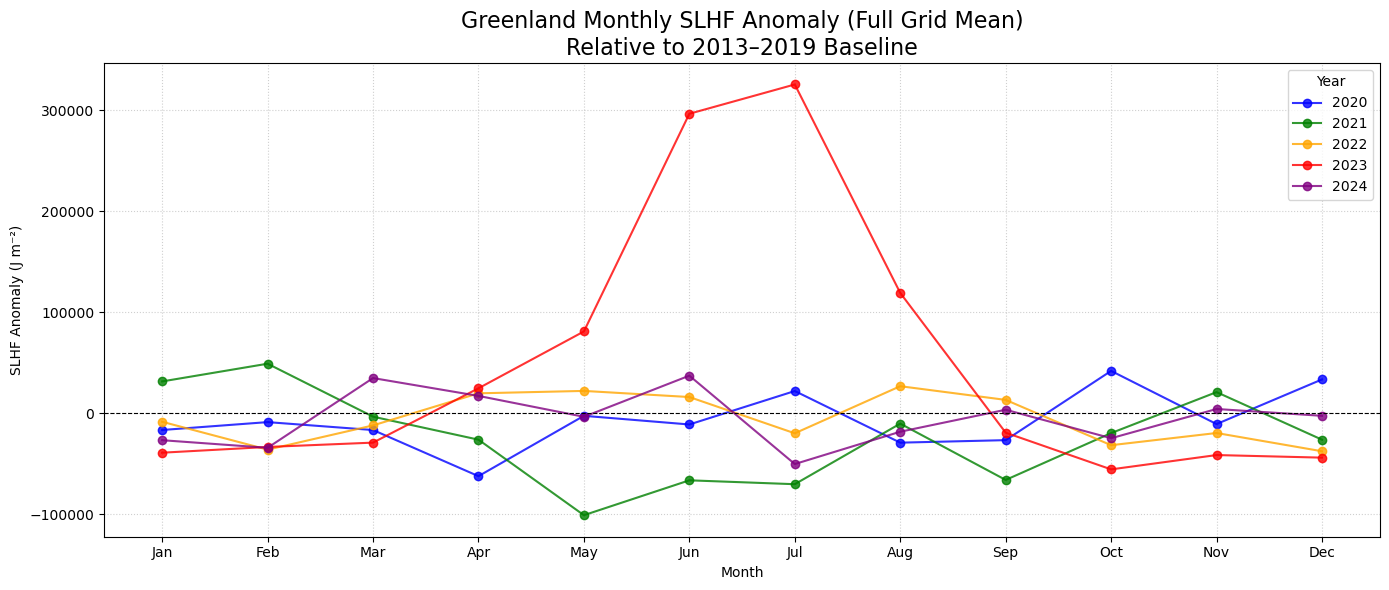


==== SLHF Monthly Anomaly Summary (2020-2024) ====
2020 Average Anomaly: -7.33e+03 J/m²
2021 Average Anomaly: -2.41e+04 J/m²
2022 Average Anomaly: -5.69e+03 J/m²
2023 Average Anomaly: 4.87e+04 J/m²
2024 Average Anomaly: -5.36e+03 J/m²

===== Processing Variable: STRD =====


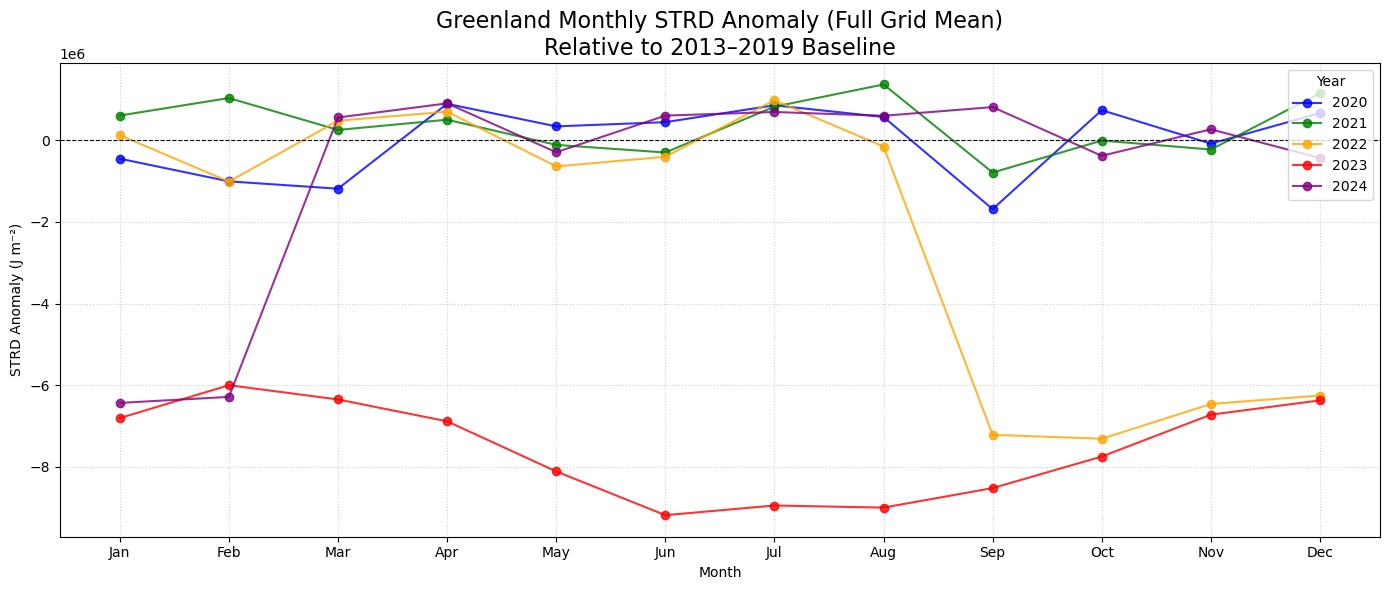


==== STRD Monthly Anomaly Summary (2020-2024) ====
2020 Average Anomaly: 3.62e+03 J/m²
2021 Average Anomaly: 3.54e+05 J/m²
2022 Average Anomaly: -2.27e+06 J/m²
2023 Average Anomaly: -7.55e+06 J/m²
2024 Average Anomaly: -7.86e+05 J/m²

===== Processing Variable: T2M =====


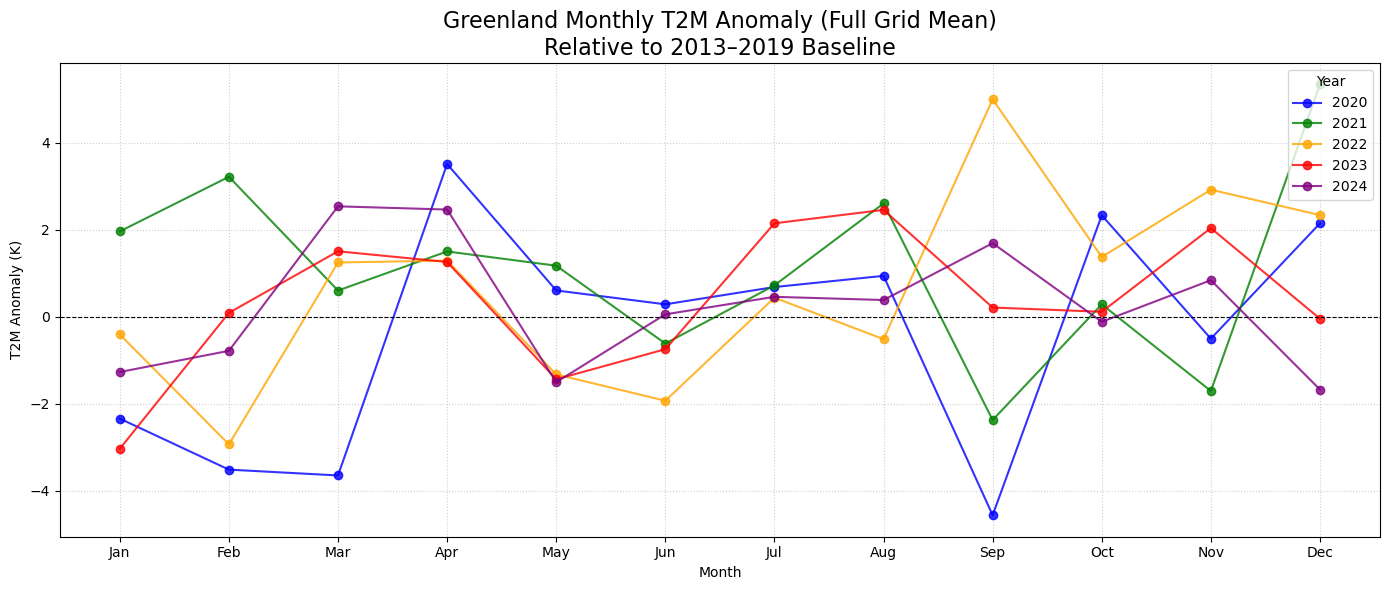


==== T2M Monthly Anomaly Summary (2020-2024) ====
2020 Average Anomaly: -0.34 K
2021 Average Anomaly: 1.06 K
2022 Average Anomaly: 0.63 K
2023 Average Anomaly: 0.38 K
2024 Average Anomaly: 0.26 K

===== Processing Variable: STR =====


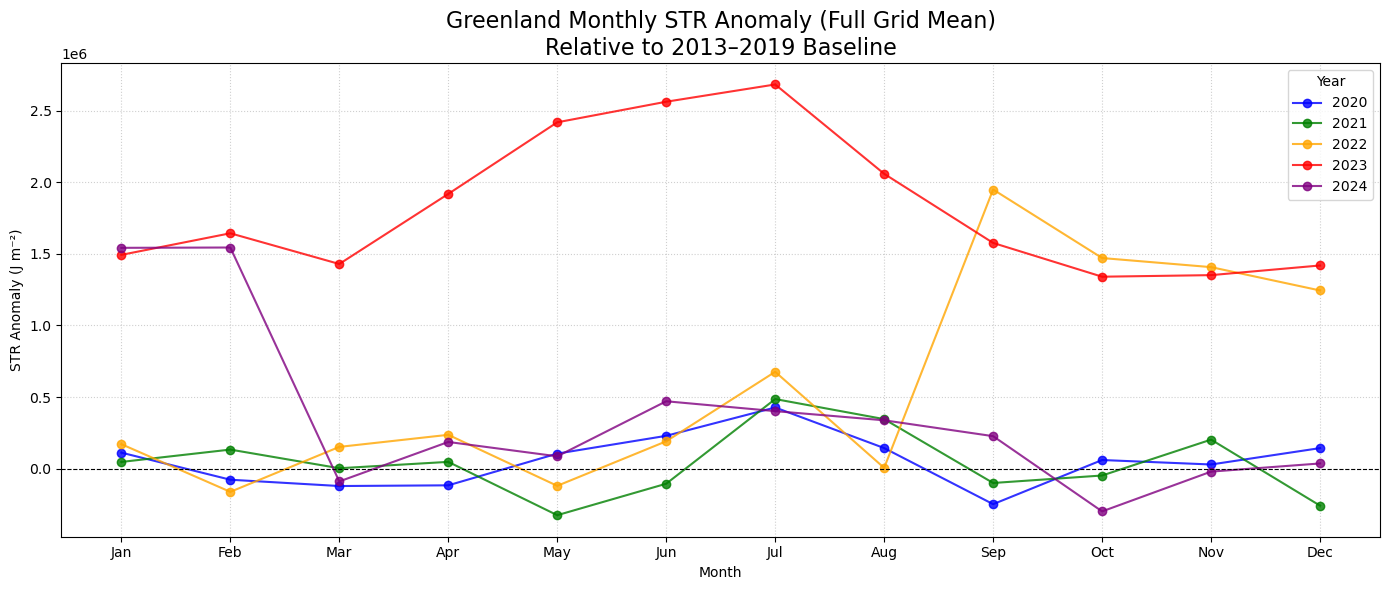


==== STR Monthly Anomaly Summary (2020-2024) ====
2020 Average Anomaly: 5.73e+04 J/m²
2021 Average Anomaly: 3.58e+04 J/m²
2022 Average Anomaly: 6.02e+05 J/m²
2023 Average Anomaly: 1.82e+06 J/m²
2024 Average Anomaly: 3.69e+05 J/m²


In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

# ===== Parameters (通用) =====
nc_path = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5LANDfeature_greenland.nc"

# 新的基线: 2013–2019 (7 年)
baseline_years = range(2013, 2020)
# 新的目标年份: 2020–2024
target_years = range(2020, 2025)

# 定义要处理的变量列表
variable_list = ["ssrd", "slhf", "strd", "t2m", "str"]

# 定义目标年份的颜色
year_colors = {
    2020: 'blue', 2021: 'green', 2022: 'orange', 2023: 'red', 2024: 'purple'
}
target_years_list = sorted(year_colors.keys())

def generate_dummy_data(var_name, times, lats, lons):
    """为演示目的生成模拟数据"""
    data_shape = (len(times), len(lats), len(lons))
    np.random.seed(42)
    # 模拟数据：考虑不同的量级和趋势
    if 'ssrd' in var_name: # 表面短波辐射向下通量 (J/m²)
        base_data = 1.5e7 + 2e6 * np.random.randn(*data_shape) + \
                    5e5 * (np.array([t.year for t in times]) - 2013).reshape(-1, 1, 1)
        base_data[base_data < 0] = 1e6 # 确保非负
    elif 't2m' in var_name: # 2米气温 (K)
        # 气温数据在 250K-280K 之间，年际变化较小
        base_data = 265 + 5 * np.sin(2 * np.pi * np.array([t.month for t in times]) / 12).reshape(-1, 1, 1) + \
                    1 * np.random.randn(*data_shape) + \
                    0.05 * (np.array([t.year for t in times]) - 2013).reshape(-1, 1, 1)
    elif 'strd' in var_name or 'str' in var_name: # 热辐射通量 (J/m²)
        base_data = 1e7 + 5e5 * np.random.randn(*data_shape)
        base_data[base_data < 0] = 5e6
    elif 'slhf' in var_name: # 潜热通量 (J/m²)
        base_data = 5e6 + 3e5 * np.random.randn(*data_shape)
    else:
        base_data = 1e7 + 1e6 * np.random.randn(*data_shape)
        
    return xr.Dataset(
        {var_name: (("time", "latitude", "longitude"), base_data)},
        coords={"time": times, "latitude": lats, "longitude": lons}
    )

def plot_anomaly(ds, var_name, baseline_years, target_years_list, year_colors):
    """
    计算并绘制给定变量的月平均格点平均异常时间序列。
    
    参数:
    ds (xr.Dataset): 包含数据的 Xarray Dataset。
    var_name (str): 要处理的变量名称。
    ... (其他绘图和年份参数)
    """
    
    print(f"\n===== Processing Variable: {var_name.upper()} =====")
    
    if var_name not in ds:
        print(f"Error: Variable '{var_name}' not found in the dataset.")
        return
        
    data_var = ds[var_name]

    # 1. 计算月平均 (Full Grid) for all years
    # data_monthly_mean: (time)
    data_monthly_mean = data_var.mean(dim=["latitude", "longitude"], skipna=True)

    # 2. 提取基线 (2013-2019) 数据
    data_baseline = data_monthly_mean.sel(
        time=data_monthly_mean.time.dt.year.isin(baseline_years)
    )

    # 3. 计算月气候平均 (mean for each month M over the baseline years)
    # data_climatology: (month)
    data_climatology = data_baseline.groupby("time.month").mean(dim="time")

    # 4. 计算月异常 (deviation from the long-term mean for that month)
    # anomaly: (time)
    anomaly = data_monthly_mean.groupby("time.month") - data_climatology

    # 5. 只选择目标年份 (2020-2024)
    anomaly_target = anomaly.sel(
        time=anomaly.time.dt.year.isin(target_years_list)
    )

    # ===== 时间序列图 =====
    plt.figure(figsize=(14, 6))

    for year in target_years_list:
        year_data = anomaly_target.sel(time=anomaly_target.time.dt.year == year)
        # 以月份索引 (1 到 12) 为 x 轴绘图
        plt.plot(
            year_data.time.dt.month, year_data,
            marker='o', linestyle='-', label=str(year),
            color=year_colors.get(year, 'gray'), alpha=0.8
        )

    plt.axhline(0, color='black', lw=0.8, linestyle='--')
    plt.title(
        f"Greenland Monthly {var_name.upper()} Anomaly (Full Grid Mean)\n"
        f"Relative to {min(baseline_years)}–{max(baseline_years)} Baseline",
        fontsize=16
    )
    # 尝试根据变量设置单位，ERA5-Land 原始单位通常是 J/m² 或 K。
    if 't2m' in var_name:
        y_label = f"{var_name.upper()} Anomaly (K)"
        # T2M 异常值通常较小，调整 y 轴标签格式
        anomaly_format = "{:.2f} K"
    elif 'ssrd' in var_name or 'strd' in var_name or 'slhf' in var_name or 'str' in var_name:
        y_label = f"{var_name.upper()} Anomaly (J m⁻²)"
        anomaly_format = "{:.2e} J/m²"
    else:
        y_label = f"{var_name.upper()} Anomaly"
        anomaly_format = "{:.2e}"
        
    plt.ylabel(y_label)
    plt.xlabel("Month")
    plt.xticks(range(1, 13),
               ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
    plt.grid(True, ls=':', alpha=0.6)
    plt.legend(title='Year', loc='upper right')
    plt.tight_layout()
    plt.show()

    # ===== 打印异常摘要 =====
    print(f"\n==== {var_name.upper()} Monthly Anomaly Summary ({min(target_years_list)}-{max(target_years_list)}) ====")
    for year in target_years_list:
        year_data = anomaly_target.sel(time=anomaly_target.time.dt.year == year)
        mean_anomaly = float(year_data.mean())
        print(f"{year} Average Anomaly: {anomaly_format.format(mean_anomaly)}")

# ===== 主执行块 =====

# 尝试读取数据
try:
    ds_main = xr.open_dataset(nc_path)
    if "valid_time" in ds_main.coords:
        ds_main = ds_main.rename({"valid_time": "time"})
except FileNotFoundError:
    print(f"Error: File not found at {nc_path}. Please check the path.")
    print("Generating DUMMY data for all variables for script structure demonstration.")
    # 生成通用时间、经纬度坐标
    years = np.concatenate([np.arange(min(baseline_years), max(target_years) + 1)])
    times = [np.datetime64(f'{y}-{m:02d}-15') for y in years for m in range(1, 13)]
    lats = np.arange(60, 90, 5)
    lons = np.arange(-50, 50, 10)
    
    # 初始化一个空的 Dataset
    ds_main = xr.Dataset(coords={"time": times, "latitude": lats, "longitude": lons})
    
    # 为每个变量生成模拟数据并合并到 ds_main
    for var_name in variable_list:
        dummy_data_ds = generate_dummy_data(var_name, times, lats, lons)
        ds_main[var_name] = dummy_data_ds[var_name]
    
    print("Dummy dataset created successfully.")

# 循环遍历变量列表并生成图表
for var_name in variable_list:
    plot_anomaly(ds_main, var_name, baseline_years, target_years_list, year_colors)